# Titanic Survival Prediction — Data Cleaning & Feature Engineering

in this notebook we clean the raw dataset and engineer features that will improve model performance   

- Handling missing values with different strategies
- Encoding categorical variables
- Feature engineering (creating new meaningful features)
- Preparing data for machine learning

### 1. Import Libraries and Load Data

In [3]:
# import and configurations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set Visual Styles for seaborn plots
sns.set_style(style='whitegrid')



#Enable inline plotting for matplotlib charts 
%matplotlib inline


In [4]:
# Data Loading
df = pd.read_csv("Data/titanic.csv")
print(f"Original shape: {df.shape}")

# Display the first 5 rows to verify the data structure
df.head()


Original shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Data Cleaning [Handling missing values]
df['Age'] = df['Age'].fillna(df['Age'].median())



In [6]:
# Explanatory Data Analysis
fig = px.histogram(
    df,
    x="Pclass",
    color="Survived",
    barmode="group",
    title="Survival Rate by Passenger Class",
    labels={"Pclass": "Socio-Economic Class", "count": "Passenger Count"}
)

# Display the clart
fig.show()

In [7]:
# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())
print(f"\nTotal Missing: {df.isnull().sum().sum()}")


Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Total Missing: 689


### 2. Handle Missing Values

Cabin has ~77% missing values, we can't reliably impute this, so we'll drop it. However, let's first check if having a cabin number is predictive

In [8]:
# Checking if having a cabin recorded affects survival

df['HasCabin'] = df['Cabin'].notna().astype(int)

print("Survival rate by HasCabin:")
print(df.groupby("HasCabin")["Survived"].mean())
print("\nPassengers with a cabin number had a much higher survival rate!")
print("We'll Keep HasCabin as a feature and drop the raw cabin column.")

Survival rate by HasCabin:
HasCabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64

Passengers with a cabin number had a much higher survival rate!
We'll Keep HasCabin as a feature and drop the raw cabin column.


In [9]:
# Drop the raw Cabin Column
df = df.drop(columns=['Cabin'])


### 2.2 Age - Impute the Group Median
 Instead of filling Age with the overall median, we'll fill it using the Median age per (Pclass, Sex) group. This is more accurate becouse age distributions differ by class and sex.

In [10]:
# Show median age by Pclass and Sex
print("Median age by Pclass and Sex:")
print(df.groupby(["Pclass", "Sex"])["Age"].median())
print(f"\nMissing Age values before imputation: {df['Age'].isnull().sum()}")

Median age by Pclass and Sex:
Pclass  Sex   
1       female    32.5
        male      36.0
2       female    28.0
        male      29.0
3       female    28.0
        male      28.0
Name: Age, dtype: float64

Missing Age values before imputation: 0


In [11]:
# Fill missing age with group Median
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining NaN with Overall Median
df["Age"] = df["Age"].fillna(df["Age"].median())

print(f"Missing Age values after imputation: {df['Age'].isnull().sum()}")

Missing Age values after imputation: 0


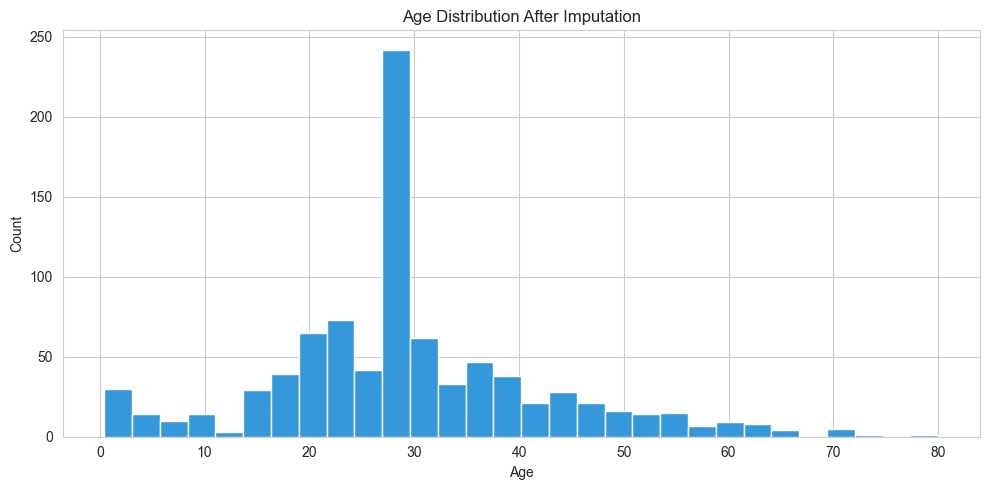

In [12]:
# Visualize the distribution of Age after imputation

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["Age"], bins=30, color="#3498db", edgecolor="white")
ax.set_title("Age Distribution After Imputation")
ax.set_xlabel("Age")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()
